# Used-Vehicle Price Estimation in Sri Lanka
### 01 / Dataset Quality, Preparation & Exploratory Analysis

**MSc Machine Learning · Final Assignment**  
**Analysis unit:** advertisement listing · **Prediction target:** advertised asking price in LKR  
**Source:** [KDU vehicle listing collection (Ikman.lk)](https://github.com/MarcWije/CarPricePredictor)

The study examines scraped Sri Lankan vehicle advertisements. This notebook audits the raw data, applies documented quality controls and exports a standardized regression dataset. Seller-advertised prices are not verified transaction values.

## 1. Raw dataset and structure

The original scrape is loaded unchanged. All transformations are applied to a separate working DataFrame to preserve source records.

In [1]:
from pathlib import Path
from datetime import datetime
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

SEED = 42
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.6), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 55)


In [2]:
# Resolve the project directory in Colab, JupyterLab or a local Python environment.
from pathlib import Path
import os

PROJECT_NAME = 'Sri_Lanka_Vehicle_Price_Jupyter_Notebooks'
DRIVE_ROOT = Path('/content/drive/MyDrive')
if Path('/content').exists() and not DRIVE_ROOT.exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass

locations = [Path.cwd(), DRIVE_ROOT / PROJECT_NAME,
             DRIVE_ROOT / 'Sri_Lanka_Vehicle_Price_Final_Assignment',
             Path('/content'), Path('/mnt/data')]
PROJECT_DIR = next((p for p in locations if (p / 'ikman-scrapes.csv').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('ikman-scrapes.csv was not found in the notebook project directory.')
RAW_CSV = PROJECT_DIR / 'ikman-scrapes.csv'
OUTPUT_DIR = PROJECT_DIR / 'vehicle_ml_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_CSV = OUTPUT_DIR / 'cleaned_vehicle_data.csv'
AUDIT_JSON = OUTPUT_DIR / 'cleaning_report.json'
print('Dataset:', RAW_CSV)
print('Outputs:', OUTPUT_DIR)

Dataset: /mnt/data/Sri_Lanka_Vehicle_Price_Final_Assignment/ikman-scrapes.csv
Outputs: /mnt/data/Sri_Lanka_Vehicle_Price_Final_Assignment/vehicle_ml_outputs


In [3]:
raw = pd.read_csv(RAW_CSV, low_memory=False)
expected_columns = [
    "Brand", "Model", "Edition", "Year of Manufacture", "Transmission",
    "Fuel Type", "Body Type", "Engine Capacity (cc)", "Mileage (km)",
    "Price Rs.", "Negotiable"
]
missing_columns = sorted(set(expected_columns) - set(raw.columns))
assert not missing_columns, f"Expected columns missing: {missing_columns}"

dataset_overview = pd.DataFrame({
    "Measure": ["Source records", "Original attributes", "Numeric-like columns", "Categorical columns"],
    "Value": [len(raw), len(expected_columns), 4, 7],
})
display(dataset_overview.style.format({"Value": "{:,.0f}"}).hide(axis='index'))
display(raw.head(6))

Measure,Value
Source records,"10,388"
Original attributes,11
Numeric-like columns,4
Categorical columns,7


,Brand,Model,Edition,Year of Manufacture,Transmission,Fuel Type,Body Type,Engine Capacity (cc),Mileage (km),Price Rs.,Negotiable
0,Audi,A3,NaN,2023,Automatic,Petrol,Saloon,"1,500 cc",0 km,"Rs 20,500,000",Yes
1,Audi,A3,SPORT BACK S LINE,2023,Automatic,Petrol,Hatchback,"1,000 cc","11,000 km","Rs 18,500,000",Yes
2,Ford,Laser,GL,1988,Manual,Petrol,Saloon,"1,500 cc","250,000 km","Rs 1,000,000",Yes
3,Ford,Laser,GL,1988,Manual,Petrol,Saloon,"1,500 cc","250,000 km","Rs 1,000,000",Yes
4,Honda,Clarity,NaN,2005,Manual,Petrol,Coupé/Sports,"1,000 cc","20,000 km","Rs 1,000,000",Yes
5,Mitsubishi,Lancer,Lancer Wagon 1200,1983,Manual,Petrol,Station wagon,"1,200 cc","67,340 km","Rs 1,000,000",No


## 2. Source-data quality assessment

Data types, missingness, category cardinality and vehicle make concentration are evaluated prior to cleaning.

In [4]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean().mul(100),
    "unique": raw.nunique(dropna=True),
})
display(profile.style.format({"missing_%": "{:.1f}%"}))
display(raw["Brand"].value_counts(dropna=False).head(12).rename_axis("Brand").to_frame("Listings"))

,dtype,missing,missing_%,unique
Brand,object,0,0.0%,57
Model,object,0,0.0%,473
Edition,object,1559,15.0%,3956
Year of Manufacture,int64,0,0.0%,65
Transmission,object,0,0.0%,4
Fuel Type,object,0,0.0%,6
Body Type,object,910,8.8%,7
Engine Capacity (cc),object,0,0.0%,276
Mileage (km),object,0,0.0%,1805
Price Rs.,object,0,0.0%,1588


,Listings
Brand,
Toyota,3568
Suzuki,1499
Honda,1207
Nissan,615
Daihatsu,501
Mercedes Benz,402
Mitsubishi,308
BMW,282
Audi,261


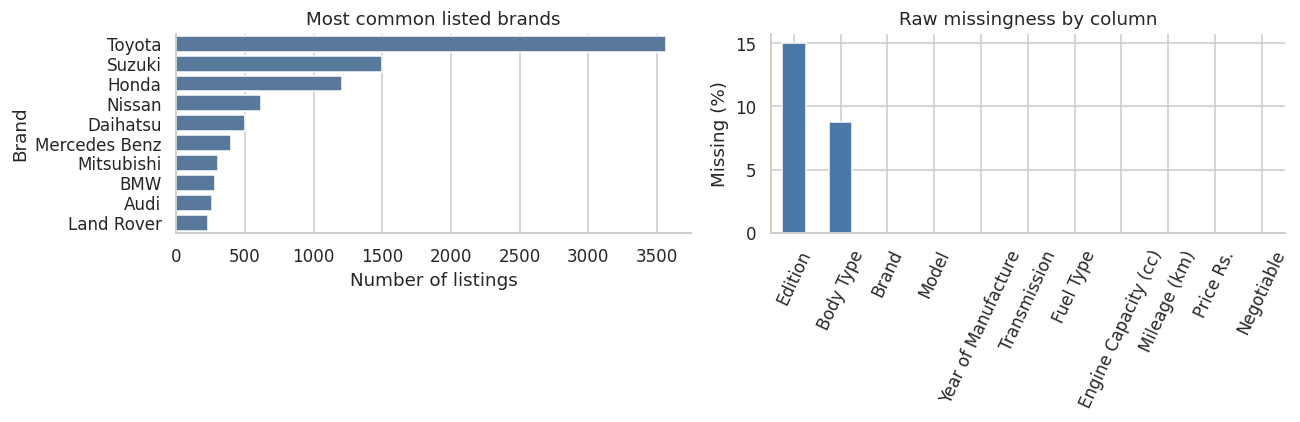

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=raw["Brand"].value_counts().head(10).values,
            y=raw["Brand"].value_counts().head(10).index, ax=axes[0], color="#4C78A8")
axes[0].set(title="Most common listed brands", xlabel="Number of listings", ylabel="Brand")
raw.isna().mean().mul(100).sort_values(ascending=False).plot(kind="bar", ax=axes[1], color="#4C78A8")
axes[1].set(title="Raw missingness by column", ylabel="Missing (%)", xlabel="")
axes[1].tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()

*Figure 1.* Distribution of advertised vehicle makes and recorded null values in the source data.

## 3. Variable normalization

Text fields are standardized for whitespace and capitalization; the numerical measures are converted from scraped currency or unit strings. Unverified category synonyms are not manually merged. Unavailable measurements remain missing for train-only imputation in Notebook 02.

In [6]:
column_names = {
    "Year of Manufacture": "ManufactureYear", "Fuel Type": "FuelType",
    "Body Type": "BodyType", "Engine Capacity (cc)": "EngineCC",
    "Mileage (km)": "MileageKM", "Price Rs.": "PriceLKR",
}
CAT = ["Brand", "Model", "Edition", "Transmission", "FuelType", "BodyType", "Negotiable"]
NUM = ["ManufactureYear", "EngineCC", "MileageKM"]
FEATURES = CAT + NUM
TARGET = "PriceLKR"

def parse_listing_number(s: pd.Series) -> pd.Series:
    """Remove units/commas/currency from values such as 'Rs 12,500,000'."""
    cleaned = s.astype("string").str.replace(r"[^\d.]", "", regex=True)
    return pd.to_numeric(cleaned.replace("", pd.NA), errors="coerce").astype(float)

def normalize_listing_text(s: pd.Series) -> pd.Series:
    """Harmonize whitespace/case, but avoid guessing brand/model synonyms."""
    s = s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    tokens = {"", "nan", "none", "null", "n/a", "na", "unknown", "not available", "-"}
    return s.mask(s.str.casefold().isin(tokens)).str.title()

df = raw[expected_columns].rename(columns=column_names).copy()
for col in CAT:
    df[col] = normalize_listing_text(df[col]).fillna("Unknown")
for col in NUM + [TARGET]:
    df[col] = parse_listing_number(df[col])

display(df.sample(min(8, len(df)), random_state=SEED))


,Brand,Model,Edition,ManufactureYear,Transmission,FuelType,BodyType,EngineCC,MileageKM,PriceLKR,Negotiable
8954,Toyota,Corolla,141 Gli,2011.0,Automatic,Petrol,Saloon,1600.0,200000.0,8400000.0,Yes
6495,Suzuki,Wagon R Stingray,Unknown,2015.0,Automatic,Hybrid,Hatchback,650.0,89000.0,5800000.0,Yes
4184,Toyota,Yaris Cross,Unknown,2025.0,Automatic,Hybrid,Suv / 4X4,1496.0,9669.0,21000000.0,No
7015,Daihatsu,Mira,Es L,2023.0,Automatic,Petrol,Hatchback,660.0,8000.0,6375000.0,Yes
5860,Suzuki,Celerio,Unknown,2015.0,Manual,Petrol,Hatchback,1000.0,49800.0,4650000.0,Yes
7467,Suzuki,Alto,Hybrid S Grade,2023.0,Automatic,Hybrid,Station Wagon,660.0,8600.0,6900000.0,Yes
4245,Honda,Vezel,Z-Play,2025.0,Automatic,Hybrid,Hatchback,1500.0,0.0,21700000.0,No
1692,Honda,Vezel,Honda Vezel Rs 2018,2018.0,Automatic,Hybrid,Suv / 4X4,1500.0,100000.0,13200000.0,Yes


## 4. Exploratory analysis of advertised prices

Vehicle asking prices are strongly right-skewed. A log-scaled view is included to represent lower- and mid-price listings while still highlighting extreme values. The raw price distribution is examined *before* anomaly removal.

,Price (LKR)
count,"10,388"
mean,"19,464,828"
std,"211,900,267"
min,"295,000"
1%,"920,000"
5%,"2,400,000"
25%,"7,150,000"
50%,"10,775,000"
75%,"18,500,000"
95%,"56,965,000"


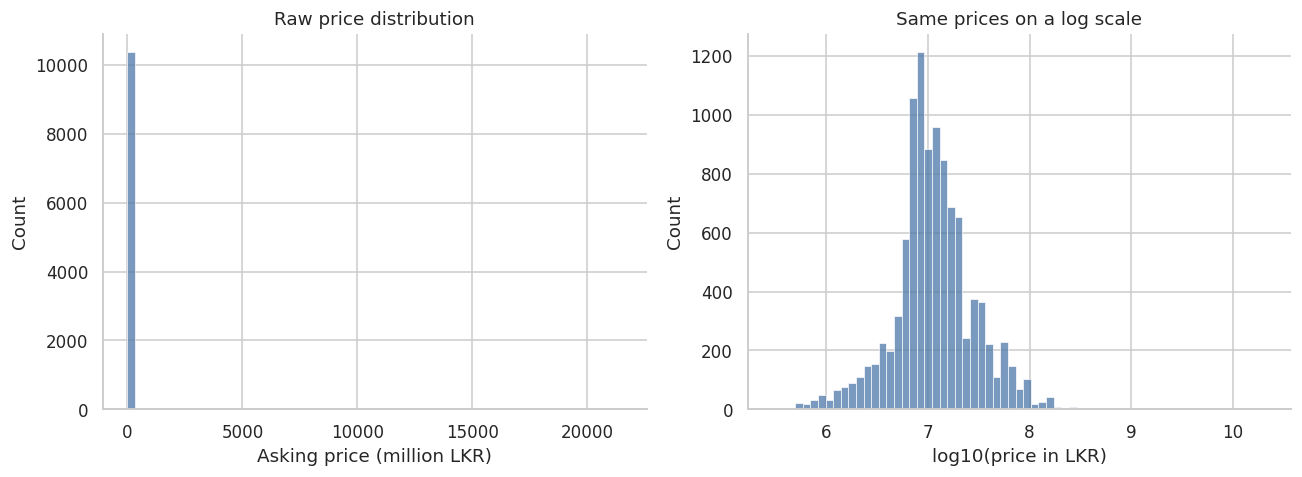

In [7]:
percentiles = df[TARGET].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
display(percentiles.rename("Price (LKR)").to_frame().style.format({"Price (LKR)": "{:,.0f}"}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df.loc[df.PriceLKR > 0, "PriceLKR"] / 1e6, bins=65, ax=axes[0], color="#4C78A8")
axes[0].set(xlabel="Asking price (million LKR)", title="Raw price distribution")
sns.histplot(np.log10(df.loc[df.PriceLKR > 0, "PriceLKR"]), bins=65, ax=axes[1], color="#4C78A8")
axes[1].set(xlabel="log10(price in LKR)", title="Same prices on a log scale")
plt.tight_layout(); plt.show()

*Figure 2.* Advertised-price distribution in the original numerical scale and on a logarithmic scale.

## 5. Documented quality-control policy

| Issue | Treatment | Rationale |
|---|---|---|
| Duplicate specification-and-price records | Retain first | Reduce identical scrape observations |
| Missing/nonpositive asking price | Exclude | Invalid supervised target |
| Price greater than LKR 1 billion | Exclude and audit | Extreme suspected entry error (study-specific threshold) |
| Manufacturing year outside 1950–execution year | Exclude | Inconsistent temporal measurement |
| Zero odometer for a vehicle built in 2022 or earlier | Set mileage missing | Likely placeholder, not verified zero |
| Mileage outside 0–800,000 km | Set missing | Conservative plausibility threshold |
| Engine displacement outside 100–8,000 cc or electric vehicle | Set missing | Inconsistent or non-applicable field |
| Unusually low recent-vehicle prices | Flag only | May be a deposit listing; ambiguous without inspection |

The plausibility cutoffs are explicit modelling assumptions, **not** objectively validated ground truth. No feature imputation or encoding is fitted to the complete dataset.

In [8]:
audit = {"source": RAW_CSV.name, "raw_rows": int(len(raw)), "rules": {}, "flags": {},
         "assumptions": ["Asking prices, not confirmed sales", "Unknown scrape date / advertisement ID"]}

is_duplicate = df.duplicated(keep="first")
audit["rules"]["exact_duplicates_removed"] = int(is_duplicate.sum())
df = df.loc[~is_duplicate].copy()

bad_label = df[TARGET].isna() | (df[TARGET] <= 0)
audit["rules"]["missing_or_nonpositive_price_removed"] = int(bad_label.sum())
df = df.loc[~bad_label].copy()

price_over_one_billion = df[TARGET] > 1_000_000_000
audit["flags"]["price_over_1b_examples"] = df.loc[
    price_over_one_billion, ["Brand", "Model", "ManufactureYear", "PriceLKR"]
].head(12).to_dict("records")
audit["rules"]["price_over_1b_removed"] = int(price_over_one_billion.sum())
df = df.loc[~price_over_one_billion].copy()

invalid_year = df.ManufactureYear.isna() | df.ManufactureYear.lt(1950) | df.ManufactureYear.gt(datetime.now().year)
audit["rules"]["invalid_year_removed"] = int(invalid_year.sum())
df = df.loc[~invalid_year].copy()
df["ManufactureYear"] = df["ManufactureYear"].astype(int)

zero_older = df.ManufactureYear.le(2022) & df.MileageKM.eq(0)
invalid_mileage = df.MileageKM.lt(0) | df.MileageKM.gt(800_000)
audit["rules"]["older_zero_mileage_set_missing"] = int(zero_older.sum())
audit["rules"]["extreme_mileage_set_missing"] = int(invalid_mileage.sum())
df.loc[zero_older | invalid_mileage, "MileageKM"] = np.nan

electric = df.FuelType.eq("Electric")
invalid_engine = df.EngineCC.lt(100) | df.EngineCC.gt(8_000)
audit["rules"]["electric_cc_set_missing"] = int((electric & df.EngineCC.notna()).sum())
audit["rules"]["implausible_cc_set_missing"] = int((~electric & invalid_engine).sum())
df.loc[electric | invalid_engine, "EngineCC"] = np.nan

low_recent = df.ManufactureYear.ge(2023) & df.PriceLKR.lt(2_000_000)
audit["rules"]["low_price_recent_flagged_not_removed"] = int(low_recent.sum())
audit["flags"]["low_price_recent_examples"] = df.loc[
    low_recent, ["Brand", "Model", "ManufactureYear", "PriceLKR"]
].head(15).to_dict("records")

cleaned = df[FEATURES + [TARGET]].reset_index(drop=True)
audit["clean_rows"] = int(len(cleaned))
audit["missing_after_cleaning"] = cleaned.isna().sum().astype(int).to_dict()
audit["price_quantiles_lkr"] = {
    str(q): float(v) for q, v in cleaned.PriceLKR.quantile([0, .01, .25, .5, .75, .99, 1]).items()
}
changes = pd.DataFrame([{"Decision": k.replace('_',' ').capitalize(), "Count": v} for k,v in audit["rules"].items()])
display(changes.style.bar(subset=["Count"], color="#b4d4e9"))
display(Markdown(f"**Retained {len(cleaned):,} of {len(raw):,} original observations.**"))

,Decision,Count
0,Exact duplicates removed,1833
1,Missing or nonpositive price removed,0
2,Price over 1b removed,1
3,Invalid year removed,0
4,Older zero mileage set missing,8
5,Extreme mileage set missing,13
6,Electric cc set missing,85
7,Implausible cc set missing,9
8,Low price recent flagged not removed,3


**Retained 8,554 of 10,388 original observations.**

## 6. Post-cleaning quality assessment

The retained records are assessed for target distribution, changes in missingness and relationships between price, year of manufacture and mileage. Plot limits are applied for visualization only; they do not alter modelling observations.

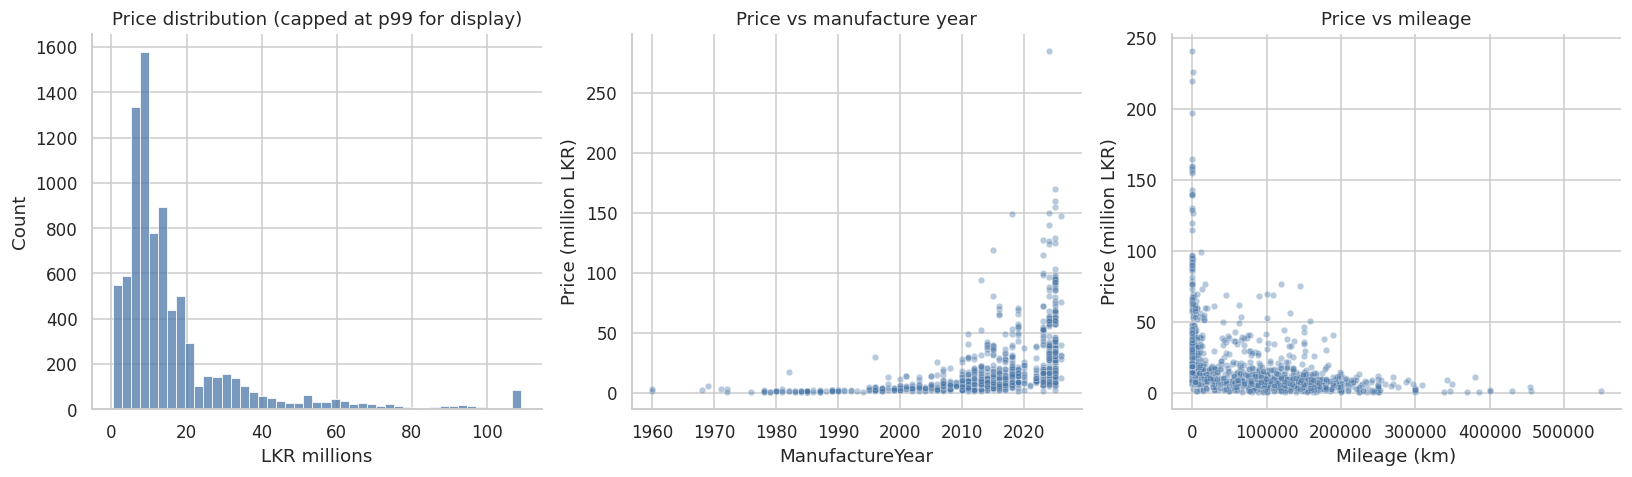

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_df = cleaned.copy()
plot_df["PriceMillions"] = plot_df.PriceLKR / 1e6
sns.histplot(plot_df.PriceMillions.clip(upper=plot_df.PriceMillions.quantile(.99)), bins=45, ax=axes[0], color="#4C78A8")
axes[0].set(title="Price distribution (capped at p99 for display)", xlabel="LKR millions")
sns.scatterplot(data=plot_df.sample(min(1500, len(plot_df)), random_state=SEED),
                x="ManufactureYear", y="PriceMillions", alpha=.4, s=18, ax=axes[1], color="#4C78A8")
axes[1].set(title="Price vs manufacture year", ylabel="Price (million LKR)")
sns.scatterplot(data=plot_df.dropna(subset=["MileageKM"]).sample(
    min(1500, plot_df.MileageKM.notna().sum()), random_state=SEED),
    x="MileageKM", y="PriceMillions", alpha=.4, s=18, ax=axes[2], color="#4C78A8")
axes[2].set(title="Price vs mileage", xlabel="Mileage (km)", ylabel="Price (million LKR)")
plt.tight_layout(); plt.show()

*Figure 3.* Final price distribution and its associations with manufacture year and mileage. Price is expressed in millions of LKR.

In [10]:
missing = pd.DataFrame({
    "Missing records": cleaned.isna().sum(),
    "Missing (%)": cleaned.isna().mean().mul(100)
}).sort_values("Missing records", ascending=False)
display(missing.style.format({"Missing (%)": "{:.2f}%"}).background_gradient(
    subset=["Missing records"], cmap="Blues"
))

review_records = df.loc[low_recent, ["Brand", "Model", "ManufactureYear", "PriceLKR"]].head(12)
display(Markdown("**Flagged recent low-price listings (retained for transparency):**"))
display(review_records)

,Missing records,Missing (%)
EngineCC,94,1.10%
MileageKM,21,0.25%
Brand,0,0.00%
Edition,0,0.00%
Model,0,0.00%
Transmission,0,0.00%
FuelType,0,0.00%
Negotiable,0,0.00%
BodyType,0,0.00%
ManufactureYear,0,0.00%


**Flagged recent low-price listings (retained for transparency):**

,Brand,Model,ManufactureYear,PriceLKR
113,Toyota,Raize,2025,1430000.0
198,Honda,Vezel,2023,1780000.0
227,Honda,Vezel,2025,1880000.0


## 7. Validation and dataset export

Schema, target validity, duplication and manufacturing-year constraints are verified before export. Missing numeric predictor values remain unresolved until the estimator is fitted on the training partition.

In [11]:
assert cleaned.PriceLKR.notna().all() and cleaned.PriceLKR.gt(0).all()
assert cleaned.ManufactureYear.between(1950, datetime.now().year).all()
assert cleaned.duplicated().sum() == 0
assert list(cleaned.columns) == FEATURES + [TARGET]
assert len(cleaned) > 1_000

cleaned.to_csv(CLEAN_CSV, index=False)
AUDIT_JSON.write_text(json.dumps(audit, indent=2, ensure_ascii=False), encoding='utf-8')

export_summary = pd.DataFrame({
    'Measure': ['Original records', 'Retained records', 'Excluded records', 'Retained proportion (%)'],
    'Result': [len(raw), len(cleaned), len(raw) - len(cleaned),
               100 * len(cleaned) / len(raw)],
})
display(export_summary.style.format({'Result': '{:,.1f}'}).hide(axis='index'))
display(Markdown(f'**Validated outputs:** `{CLEAN_CSV.name}` and `{AUDIT_JSON.name}`'))
display(cleaned.head(5))

Measure,Result
Original records,"10,388.0"
Retained records,"8,554.0"
Excluded records,"1,834.0"
Retained proportion (%),82.3


**Validated outputs:** `cleaned_vehicle_data.csv` and `cleaning_report.json`

,Brand,Model,Edition,Transmission,FuelType,BodyType,Negotiable,ManufactureYear,EngineCC,MileageKM,PriceLKR
0,Audi,A3,Unknown,Automatic,Petrol,Saloon,Yes,2023,1500.0,0.0,20500000.0
1,Audi,A3,Sport Back S Line,Automatic,Petrol,Hatchback,Yes,2023,1000.0,11000.0,18500000.0
2,Ford,Laser,Gl,Manual,Petrol,Saloon,Yes,1988,1500.0,250000.0,1000000.0
3,Honda,Clarity,Unknown,Manual,Petrol,Coupé/Sports,Yes,2005,1000.0,20000.0,1000000.0
4,Mitsubishi,Lancer,Lancer Wagon 1200,Manual,Petrol,Station Wagon,No,1983,1200.0,67340.0,1000000.0


### Preparation summary

The audit table above reports retention, exclusions and remaining incomplete measurements. Exact duplicates and one extreme asking-price error account for nearly all excluded observations. Subsequent modelling retains missing numeric predictors and fits their imputation values on training folds only.

## 8. Findings and limitations

**Predictor coverage.** Manufacturing year, mileage and engine displacement are represented, alongside brand, model, edition, fuel type, transmission, body type and price negotiability. The retained dataset spans multiple makes and vehicle classes.  
**Distribution.** The price target is right-skewed; log-target modelling is therefore assessed in the regression study while all reported prediction errors remain in LKR.  
**Limitations.** Scrape timestamps, listing IDs, verified transaction values and seller-confirmed mechanical condition are unavailable. Price outliers and down-payment advertisements may remain after automated quality controls.  
**Research output.** `vehicle_ml_outputs/cleaned_vehicle_data.csv` supplies the identical feature schema required by Notebook 02; `cleaning_report.json` preserves cleaning decisions and counts.